Training Using Gini

 GINI RESULTS

 Confusion Matrix: 

            Pred drugA  Pred drugB  Pred drugC  Pred drugX  Pred drugY
Real drugA           3           0           0           0           0
Real drugB           0           8           0           0           0
Real drugC           0           0           0           5           0
Real drugX           0           0           0          12           1
Real drugY           0           0           0           0          31

 Accuracy: 
 90.0

 Classification Report: 
               precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         3
       drugB       1.00      1.00      1.00         8
       drugC       0.00      0.00      0.00         5
       drugX       0.71      0.92      0.80        13
       drugY       0.97      1.00      0.98        31

    accuracy                           0.90        60
   macro avg       0.73      0.78      0.76        60
weighted avg       0.84      0.90    

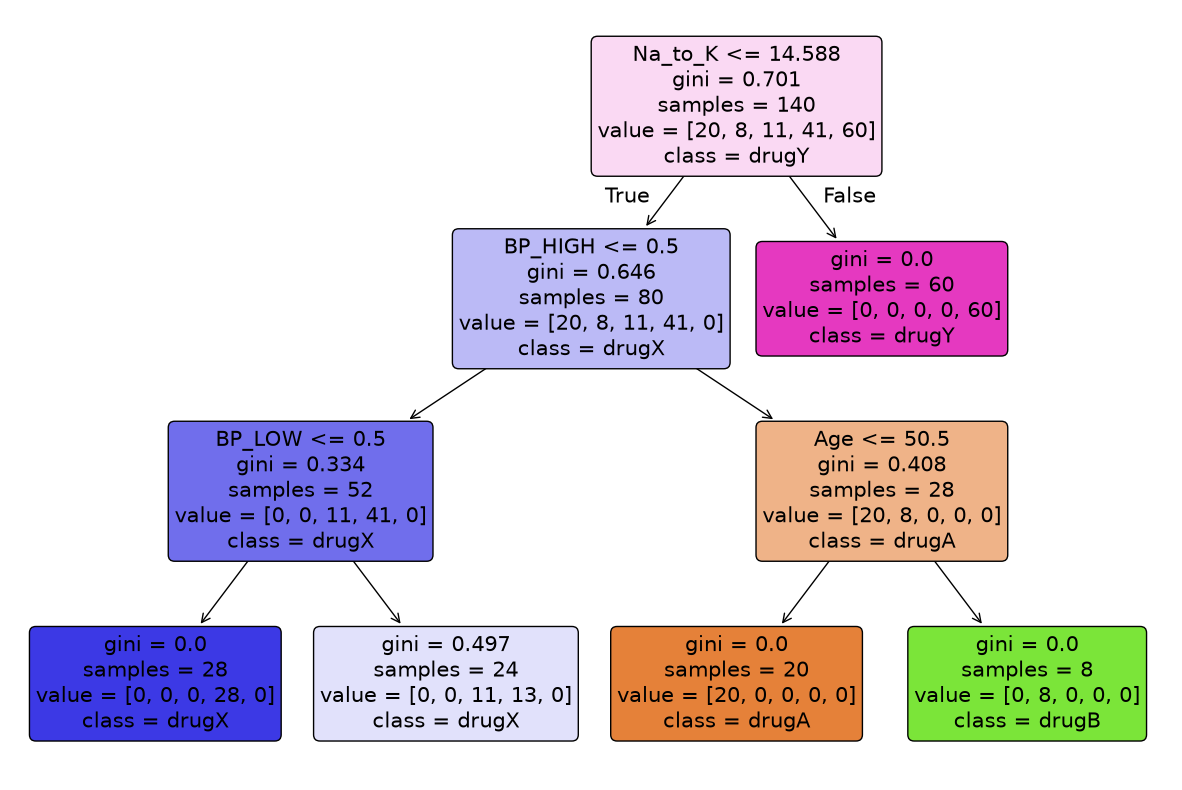

Training Using Entropy

 ENTROPY RESULTS

 Confusion Matrix: 

            Pred drugA  Pred drugB  Pred drugC  Pred drugX  Pred drugY
Real drugA           3           0           0           0           0
Real drugB           0           8           0           0           0
Real drugC           0           0           0           5           0
Real drugX           0           0           0          12           1
Real drugY           0           0           0           0          31

 Accuracy: 
 90.0

 Classification Report: 
               precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         3
       drugB       1.00      1.00      1.00         8
       drugC       0.00      0.00      0.00         5
       drugX       0.71      0.92      0.80        13
       drugY       0.97      1.00      0.98        31

    accuracy                           0.90        60
   macro avg       0.73      0.78      0.76        60
weighted avg       0.84      0.

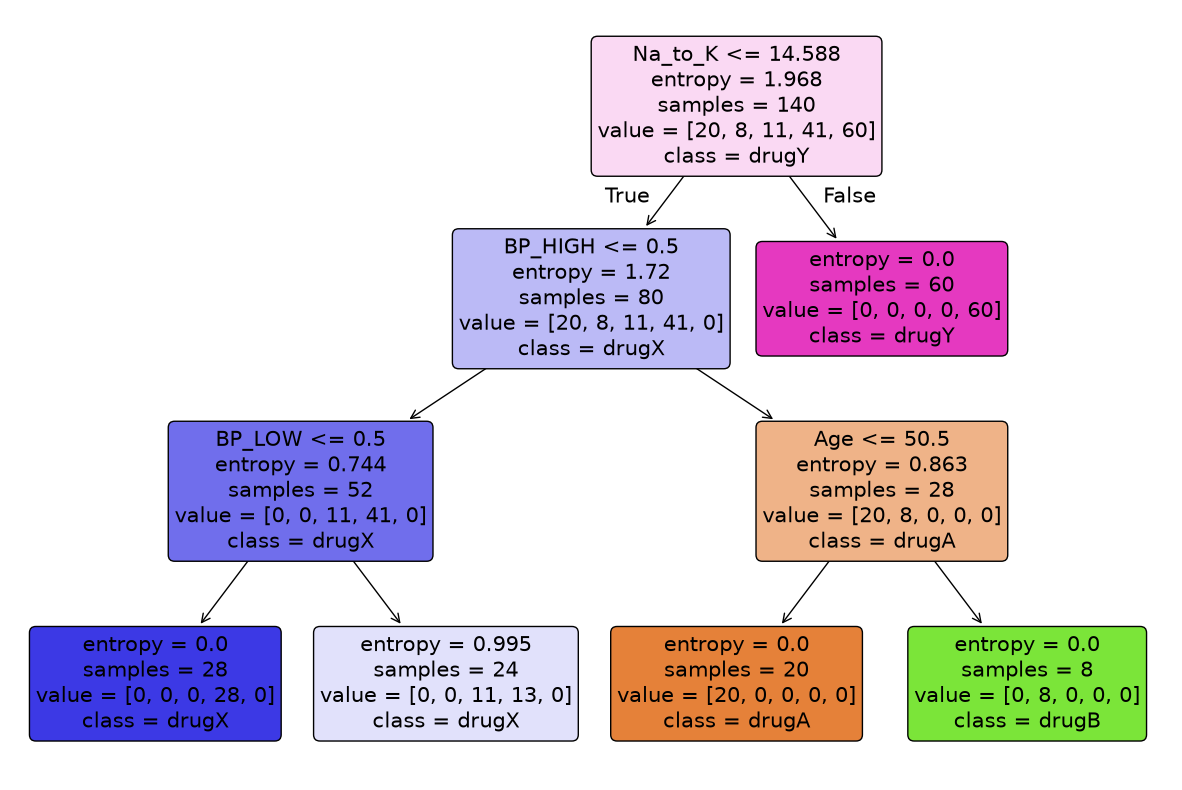

In [14]:
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

balance_data=pd.read_csv("/Users/yuktaranjalkar/Downloads/drug200.csv")

def splitdataset(balance_data):
    X=pd.get_dummies(balance_data.drop("Drug", axis=1))
    Y = balance_data["Drug"]
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=100)
    return X,Y,X_train, X_test, y_train, y_test

def train_using_gini(X_train, y_train):
    clf_gini=DecisionTreeClassifier(criterion="gini", random_state=100, max_depth=3, min_samples_leaf=5)
    clf_gini.fit(X_train, y_train)
    return clf_gini

def train_using_entropy(X_train, y_train):
    clf_entropy=DecisionTreeClassifier(criterion="entropy", random_state=100, max_depth=3, min_samples_leaf=5)
    clf_entropy.fit(X_train, y_train)
    return clf_entropy

def prediction(X_test, clf_object):
    y_pred=clf_object.predict(X_test)
    return y_pred

def cal_accuracy(y_test, y_pred, title=""):
    labels=sorted(y_test.unique())

    print(f"\n{'='*50}")
    print(f" {title}")
    print(f"{'='*50}")

    cm=pd.DataFrame(
        confusion_matrix(y_test,y_pred,labels=labels),
        index=[f"Real {l}" for l in labels],
        columns=[f"Pred {l}" for l in labels],
    )
    print("\n Confusion Matrix: \n")
    print(cm)
    print("\n Accuracy: \n", accuracy_score(y_test, y_pred)*100)
    print("\n Classification Report: \n", classification_report(y_test, y_pred, zero_division=0))

def plot_decision_tree(clf_object, feature_names, class_names):
    plt.figure(figsize=(15,10))
    plot_tree(clf_object, filled=True, feature_names=feature_names, class_names=class_names, rounded=True)
    plt.show()

if __name__=="__main__":
    X,Y,X_train,X_test,y_train, y_test=splitdataset(balance_data)

    print("Training Using Gini")
    clf_gini=train_using_gini(X_train,y_train)
    y_pred_gini=prediction(X_test, clf_gini)
    cal_accuracy(y_test, y_pred_gini, "GINI RESULTS")

    plot_decision_tree(clf_gini, X.columns, sorted(Y.unique()))

    print("Training Using Entropy")
    clf_entropy=train_using_entropy(X_train,y_train)
    y_pred_entropy=prediction(X_test, clf_entropy)
    cal_accuracy(y_test, y_pred_entropy, "ENTROPY RESULTS")

    
    plot_decision_tree(clf_entropy, X.columns, sorted(Y.unique()))


